# File 7: Communities (Auckland)

## Purpose
Where do Auckland's communities live, how has that changed since 2013, and what does renting cost where each community
is concentrated? File 3 Step 4 listed the top SA2s for each group in 2023. This file goes further:
1. How fast each community grew from 2013 to 2023
2. **Where** each is concentrated: share, head count and **location quotient** (local share ÷ Auckland share)
3. **How concentrated** each is overall (dissimilarity index), and whether that is rising or falling
4. Where new hubs are forming (biggest share gains 2013–2023)
5. Rent, affordability, crime and schools **in the areas where each community's members live**
6. A hub profile per community, ready for the dashboard and the AI agent

## Groups (14)
| Type | Groups |
|---|---|
| Ethnicity (broad, Stats NZ level 1) | European, Māori, Pacific, Asian, MELAA (Middle Eastern / Latin American / African) |
| Religion | Christian, No religion, Muslim, Hindu, Buddhist |
| Birthplace | Born in Asia, born in the Pacific Islands, born in the Middle East or Africa |
| Language | Samoan speakers |

People can report several ethnicities, religions and languages, so shares add to more than 100%.

## Inputs
| File | What |
|---|---|
| `data/census/census_2013_2018_2023_individuals_sa2.csv` | Census 2013, 2018, 2023 counts by SA2 (2023 boundaries) |
| `master_flagged.csv`, `area_profiles_by_sa2.csv`, `rent_metrics_by_sa2.csv`, `rent_market_by_sa2.csv` | Rent, flags, area types, affordability, cooling (Files 1–5) |

## Not covered here
**Detailed ethnicity** (Indian, Chinese, Samoan, Tongan, Filipino, Korean…) is not in these census files; it needs a
separate Stats NZ download (Aotearoa Data Explorer). Birthplace and Samoan language partly stand in for it.
Places of worship, halal shops and community centres are not in the data.

## Steps
1. Load community counts for 2013, 2018, 2023
2. Auckland: how each community grew
3. How concentrated is each community?
4. Hubs: where each community lives
5. Change 2013–2023: new and growing hubs
6. Rent and affordability in the areas where members live
7. Hub profiles
8. Maps
9. Save outputs

In [1]:
# STEP 0: SETUP
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, NullFormatter

CLEAN = Path('data/clean')
VIZ = Path('visualizations'); VIZ.mkdir(exist_ok=True)

# Palette: categorical slots 1-2, single-hue sequential, orange-grey-blue diverging
BLUE, ORANGE, GREY, INK, MUTED = '#2a78d6', '#eb6834', '#b9b8b3', '#0b0b0b', '#52514e'
SEQ = 'Blues'
DIV = LinearSegmentedColormap.from_list('div', [ORANGE, '#e6e5e1', BLUE])
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': GREY, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': True, 'grid.color': '#ecebe8', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'font.size': 10,
})
dollars = FuncFormatter(lambda v, _: f'${v/1e6:.1f}m' if v >= 1e6 else f'${v/1e3:.0f}k')
CV_TICKS = [1e5, 3e5, 5e5, 1e6, 2e6, 5e6, 1e7, 3e7]

def cv_axis(ax, lo, hi):
    ax.set_xscale('log'); ax.set_xticks([t for t in CV_TICKS if lo <= t <= hi])
    ax.xaxis.set_major_formatter(dollars); ax.xaxis.set_minor_formatter(NullFormatter())
pd.set_option('display.width', 160, 'display.max_columns', 40)

### Step 1: Load community counts for 2013, 2018, 2023

In [2]:
# STEP 1: COMMUNITY COUNTS. Each group = (numerator column per year, denominator = that topic's 'Total stated' per year).
# Field codes from data/census/census_2013_2018_2023_individuals_sa2_fields.csv. -999 = suppressed by Stats NZ.
YEARS = [2013, 2018, 2023]
DEN = {'ethnicity': [146, 157, 168], 'religion': [389, 402, 415], 'birthplace': [111, 123, 135], 'language': [195, 204, 213]}
GROUPS = {  # name: (type, [2013, 2018, 2023] column numbers)
    'European': ('ethnicity', [136, 147, 158]), 'Māori': ('ethnicity', [137, 148, 159]),
    'Pacific': ('ethnicity', [138, 149, 160]), 'Asian': ('ethnicity', [139, 150, 161]),
    'MELAA': ('ethnicity', [140, 151, 162]),
    'Christian': ('religion', [379, 392, 405]), 'No religion': ('religion', [377, 390, 403]),
    'Muslim': ('religion', [381, 394, 407]), 'Hindu': ('religion', [380, 393, 406]),
    'Buddhist': ('religion', [378, 391, 404]),
    'Born in Asia': ('birthplace', [106, 118, 130]), 'Born in Pacific Is.': ('birthplace', [102, 114, 126]),
    'Born in Middle East/Africa': ('birthplace', [107, 119, 131]),
    'Samoan speakers': ('language', [189, 198, 207]),
}
# Judaism is left out: its 2018 and 2023 Auckland totals are identical (2,589), as are Spiritualism's (5,181),
# which points to an error in the Stats NZ file rather than real counts.

raw = pd.read_csv('data/census/census_2013_2018_2023_individuals_sa2.csv', low_memory=False).replace(-999, np.nan)
raw['sa2_code'] = raw['SA22023_V1_00'].astype(int)
base = (pd.read_csv(CLEAN / 'master_flagged.csv',
                    usecols=['sa2_code', 'sa2_name', 'population_2023', 'median_rent_weekly', 'crime_per_1000_residents',
                             'median_household_income', 'schools', 'analysis_ready', 'flag_borrowed_rent'])
          .merge(pd.read_csv(CLEAN / 'area_profiles_by_sa2.csv', usecols=['sa2_code', 'area_type']), on='sa2_code'))
raw = raw[raw.sa2_code.isin(base.sa2_code)]

rows = []
for g, (t, nums) in GROUPS.items():
    for y, n, d in zip(YEARS, nums, DEN[t]):
        rows.append(pd.DataFrame({'sa2_code': raw.sa2_code, 'group': g, 'group_type': t, 'year': y,
                                  'count': raw[f'VAR_1_{n}'].values, 'stated': raw[f'VAR_1_{d}'].values}))
long = pd.concat(rows, ignore_index=True)
long['pct'] = 100 * long['count'] / long['stated']
print(f'SA2s with census rows: {raw.sa2_code.nunique()} of {len(base)} | rows: {len(long):,}')
assert long.pct.dropna().between(0, 100).all()

SA2s with census rows: 627 of 633 | rows: 26,334


  raw['sa2_code'] = raw['SA22023_V1_00'].astype(int)


**Reading this:** 627 of the 633 Auckland SA2s have census rows (the other 6 are water areas or uninhabited islands).
All three censuses are on **2023 SA2 boundaries**: Stats NZ re-cut the 2013 and 2018 counts, so the years compare
like for like. The 2013 census missed more people (about 6% gave no ethnicity, against almost none in 2018 and 2023), so each
share uses that year's *total stated* as the denominator.

### Step 2: Auckland, how each community grew

In [3]:
# STEP 2: AUCKLAND TOTALS. Counts and shares by year; growth 2013 -> 2023.
akl = long.groupby(['group', 'group_type', 'year'])[['count', 'stated']].sum().reset_index()
akl['pct'] = 100 * akl['count'] / akl['stated']
t = akl.pivot(index=['group', 'group_type'], columns='year', values=['count', 'pct'])
t.columns = [f'{a}_{y}' for a, y in t.columns]
t = t.reset_index().set_index('group').loc[list(GROUPS)]
t['growth_2013_2023_pct'] = 100 * (t.count_2023 / t.count_2013 - 1)
t['share_change_pp'] = t.pct_2023 - t.pct_2013
summary = t.copy()
show = t[['group_type', 'count_2013', 'count_2023', 'pct_2013', 'pct_2023', 'growth_2013_2023_pct']].copy()
for c in ['count_2013', 'count_2023']: show[c] = show[c].map('{:,.0f}'.format)
st = akl[akl.group == 'European'].set_index('year').stated
print(f'Auckland population stating an ethnicity, 2013 -> 2023: {st[2013]:,.0f} -> {st[2023]:,.0f} (+{100 * (st[2023] / st[2013] - 1):.0f}%)')
show.round(1)

Auckland population stating an ethnicity, 2013 -> 2023: 1,331,412 -> 1,656,405 (+24%)


,group_type,count_2013,count_2023,pct_2013,pct_2023,growth_2013_2023_pct
group,,,,,,
European,ethnicity,"789,261","825,114",59.3,49.8,4.5
Māori,ethnicity,"142,788","203,559",10.7,12.3,42.6
Pacific,ethnicity,"194,946","275,040",14.6,16.6,41.1
Asian,ethnicity,"307,257","518,124",23.1,31.3,68.6
MELAA,ethnicity,"24,945","44,736",1.9,2.7,79.3
Christian,religion,"615,864","578,559",47.6,34.9,-6.1
No religion,religion,"489,888","742,443",37.8,44.8,51.6
Muslim,religion,"31,131","48,108",2.4,2.9,54.5
Hindu,religion,"61,404","90,273",4.7,5.4,47.0


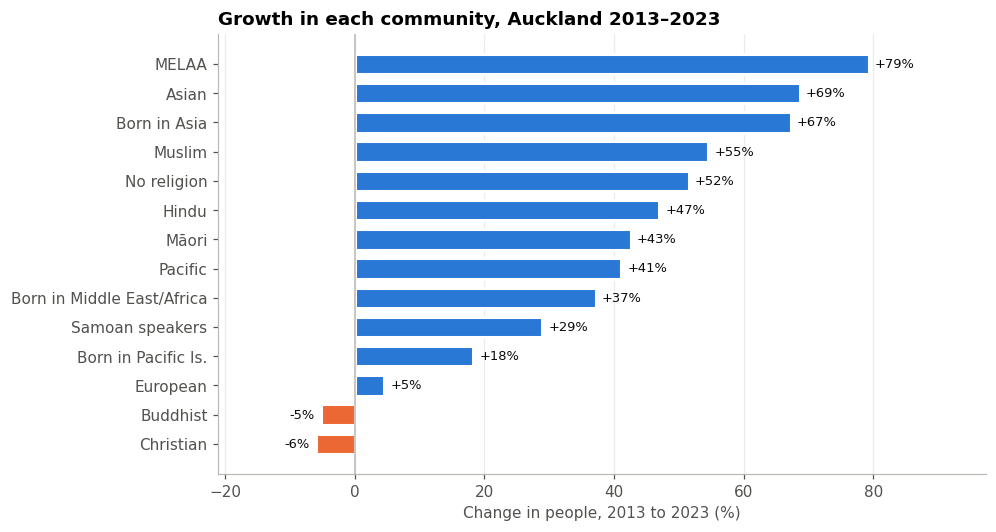

In [4]:
s = t.growth_2013_2023_pct.sort_values()
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(range(len(s)), s.values, color=[ORANGE if v < 0 else BLUE for v in s.values], height=0.7,
        edgecolor='white', linewidth=2)
for y, v in enumerate(s.values):
    ax.annotate(f'{v:+.0f}%', (v, y), xytext=(4 if v >= 0 else -4, 0), textcoords='offset points',
                ha='left' if v >= 0 else 'right', va='center', fontsize=8.5, color=INK)
ax.set_yticks(range(len(s)), s.index); ax.grid(axis='y', visible=False); ax.axvline(0, color=GREY, lw=1)
ax.set(title='Growth in each community, Auckland 2013–2023', xlabel='Change in people, 2013 to 2023 (%)')
ax.set_xlim(s.min() - 15, s.max() + 18)
fig.savefig(VIZ / '07_community_growth.png'); plt.show()

**Reading this:**
- Auckland's stated population grew about 24% from 2013 to 2023, but unevenly. **Asian (+69%), MELAA (+79%), Muslim (+55%), Hindu (+47%), Māori (+43%) and Pacific (+41%)** all grew far faster than **European (+5%)**.
- **Asian Aucklanders went from 23% to 31%** of the population; European fell from 59% to 50%.
- **Muslims: 31,100 → 48,100 (2.4% → 2.9%). Hindus: 61,400 → 90,300 (4.7% → 5.4%).**
- Christians fell 6% in number (48% → 35%), while 'No religion' became the largest answer (45%). Buddhists fell slightly.
- Pacific-born grew only 18% while Pacific ethnicity grew 41%: Pacific growth is now mostly NZ-born children and grandchildren.

*For housing demand:* the fastest-growing communities set where demand grows. Step 5 shows where they settled.

### Step 3: How concentrated is each community?

In [5]:
# STEP 3: DISSIMILARITY INDEX D = 0.5 * sum_i | g_i/G - r_i/R |, g = group in SA2 i, r = everyone else (stated - g).
# D is the share of the group that would have to move SA2 for it to be spread like everyone else.
# 0 = spread evenly, 1 = fully separate. Same SA2s in every year WITHIN each community: a community x SA2 pair is kept
# only if it has a valid count and denominator in all 3 years.
w = long.dropna(subset=['count', 'stated'])
w = w[w.groupby(['group', 'sa2_code']).year.transform('nunique') == 3]
def dissimilarity(d):
    g, r = d['count'], d['stated'] - d['count']
    return 0.5 * (g / g.sum() - r / r.sum()).abs().sum()
D = w.groupby(['group', 'year']).apply(dissimilarity, include_groups=False).unstack().loc[list(GROUPS)]
D['change'] = D[2023] - D[2013]
summary['dissimilarity_2013'], summary['dissimilarity_2023'] = D[2013], D[2023]
n = w.groupby('group').sa2_code.nunique()
print(f'SA2s used per community: {n.min()}-{n.max()}')
D.round(2)

SA2s used per community: 616-620


year,2013,2018,2023,change
group,,,,
European,0.43,0.42,0.41,-0.02
Māori,0.31,0.30,0.27,-0.03
Pacific,0.55,0.53,0.50,-0.05
Asian,0.39,0.36,0.34,-0.04
MELAA,0.27,0.24,0.22,-0.06
Christian,0.14,0.15,0.15,0.01
No religion,0.19,0.21,0.23,0.04
Muslim,0.39,0.36,0.33,-0.06
Hindu,0.41,0.39,0.37,-0.04


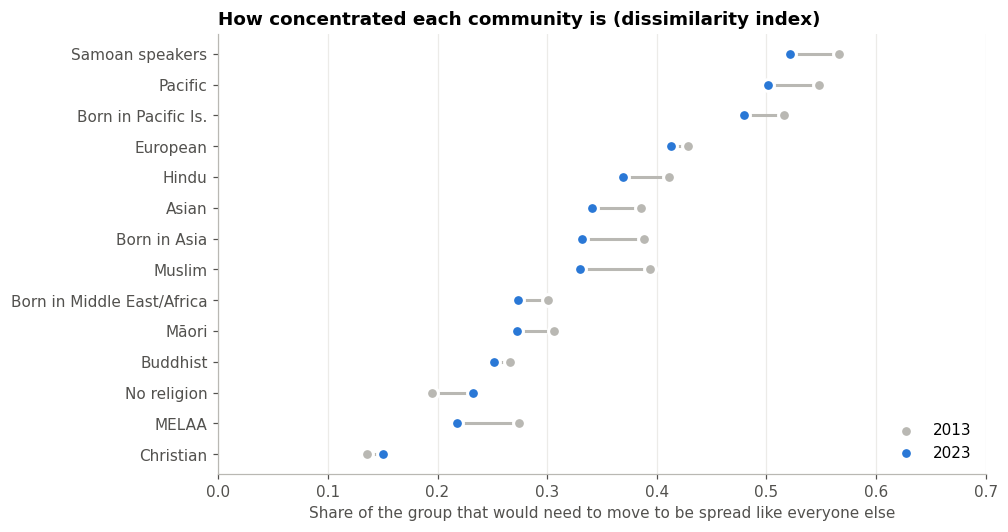

In [6]:
d = D.sort_values(2023)
fig, ax = plt.subplots(figsize=(9, 5.2))
for y, (g, r) in enumerate(d.iterrows()):
    ax.plot([r[2013], r[2023]], [y, y], color=GREY, lw=2, zorder=1)
ax.scatter(d[2013], range(len(d)), s=60, color=GREY, edgecolor='white', linewidth=2, zorder=2, label='2013')
ax.scatter(d[2023], range(len(d)), s=60, color=BLUE, edgecolor='white', linewidth=2, zorder=3, label='2023')
ax.set_yticks(range(len(d)), d.index); ax.grid(axis='y', visible=False); ax.set_xlim(0, 0.7)
ax.legend(frameon=False, loc='lower right')
ax.set(title='How concentrated each community is (dissimilarity index)',
       xlabel='Share of the group that would need to move to be spread like everyone else')
fig.savefig(VIZ / '07_dissimilarity.png'); plt.show()

**Reading this:**
- **Pacific and Samoan-speaking Aucklanders are the most concentrated** (D about 0.5: half would have to move to be spread like everyone else). Hindu (0.37), Asian (0.34) and Muslim (0.33) are moderately concentrated; Christians (0.15) are spread almost evenly.
- **Almost every community became less concentrated from 2013 to 2023.** Muslims (0.39 → 0.33), the Asian-born (0.39 → 0.33) and MELAA (0.27 → 0.22) dispersed fastest: new arrivals settled across many suburbs, not only the traditional hubs.
- Only 'No religion' and Christian became slightly *more* concentrated, as the two drifted apart geographically.

*Method:* the **dissimilarity index** is the standard segregation measure. Each community is measured on the same SA2s in all three years (pairs missing a year are left out); compared with requiring all three years per SA2 across every community, this moves no value by more than 0.0015 (largest: Buddhist 2023). It depends on the unit, so SA2-level values can't be compared with studies using other units. It ignores *which* SA2s are next to each other.

### Step 4: Hubs, where each community lives

In [7]:
# STEP 4: LOCATION QUOTIENT (LQ) = SA2 share / Auckland share. LQ 2 = twice as common as across Auckland.
# A HUB = analysis-ready SA2, LQ >= 2 and at least 300 people of that group (so tiny SA2s can't qualify on share alone).
c23 = long[long.year == 2023].merge(summary['pct_2023'].rename('akl_pct'), left_on='group', right_index=True)
c23['lq'] = c23.pct / c23.akl_pct
c23 = c23.merge(base, on='sa2_code')
c23['is_hub'] = c23.analysis_ready & (c23.lq >= 2) & (c23['count'] >= 300)
rows = []
for g in GROUPS:
    x = c23[(c23.group == g) & c23.analysis_ready]
    top = x.nlargest(5, 'count')
    hub = x[x.is_hub]
    rows.append({'Group': g, 'Hubs': len(hub), '% of group living in hubs': round(100 * hub['count'].sum() / x['count'].sum()),
                 'Largest by head count': ', '.join(f'{n} ({v:,.0f})' for n, v in zip(top.sa2_name, top['count']))})
summary['hubs'] = [r['Hubs'] for r in rows]
summary['pct_in_hubs'] = [r['% of group living in hubs'] for r in rows]
pd.set_option('display.max_colwidth', 140)
pd.DataFrame(rows).set_index('Group')

,Hubs,% of group living in hubs,Largest by head count
Group,,,
European,0,0,"Te Puru (3,981), Narrow Neck (3,792), Orewa North (3,735), Red Beach East (3,618), Puhoi Valley (3,603)"
Māori,40,19,"Papakura Eastburn (1,677), Pukekohe West (1,563), Rowandale East (1,287), Rosehill (1,245), Papakura North (1,215)"
Pacific,82,49,"Harania North (3,270), Ōtara East (3,018), Sutton Park (2,991), Māngere West (2,703), Māngere Mascot (2,667)"
Asian,30,12,"Ormiston Central (3,549), Ormiston South (3,321), Mission Heights South (2,838), Takanini South (2,784), Baverstock (2,772)"
MELAA,2,1,"Unsworth Heights West (321), Waterview (315), Mount Roskill Central South (261), Unsworth Heights East (255), Hobsonville Point Park (240)"
Christian,0,0,"Harania North (2,706), Sutton Park (2,610), Māngere Mascot (2,391), Ōtara East (2,385), Māngere West (2,370)"
No religion,0,0,"Hobsonville Point Park (3,015), Whenuapai (2,865), Narrow Neck (2,787), Kumeū-Huapai North (2,766), Hauraki (2,736)"
Muslim,13,11,"Māngere South (669), Wesley West (516), Māngere South East (507), Avondale South (Auckland) (489), Mount Roskill Central South (444)"
Hindu,71,39,"Puhinui North (921), Ormiston South (816), Mount Roskill Central East (786), Hilltop (Auckland) (759), Mount Roskill West (756)"


**Reading this:**
- A **hub** here means an analysis-ready SA2 where the group is at least twice as common as across Auckland (LQ ≥ 2) and numbers 300+ people.
- **Pacific (82 hubs, 49% of all Pacific Aucklanders live in one), Samoan speakers (54%) and Hindu (71 hubs, 39%)** are strongly hub-based.
- **Muslims are spread out:** 13 hubs hold only 11% of Auckland Muslims. The largest numbers live in Māngere South, Wesley West, Māngere South East, Avondale South and Mount Roskill Central South.
- **Asian Aucklanders** are 31% of the city, so few SA2s can be twice that (30 hubs). The largest numbers are in the south-east growth areas: Ormiston, Mission Heights, Takanini.
- **Born in Middle East/Africa** includes South Africans, which is why its largest numbers are on the North Shore and in Millwater, not in Mount Roskill. MELAA (ethnicity) is the better measure for Middle Eastern and African communities, and it has only 2 hubs.
- European, Christian, No religion and Buddhist have no hubs: they are too widespread (or too small, for Buddhists) to reach twice the Auckland share with 300 people.

### Step 5: Change 2013–2023, new and growing hubs

In [8]:
# STEP 5: SHARE GAIN 2013 -> 2023 in percentage points, for the communities that grew fastest.
# Only SA2s with 500+ residents in both years and 100+ of the group in 2023 (small 2013 counts are noisy).
p = long.pivot_table(index=['sa2_code', 'group'], columns='year', values=['pct', 'count', 'stated']).dropna()
p.columns = [f'{a}_{y}' for a, y in p.columns]
p = p.reset_index().merge(base[['sa2_code', 'sa2_name', 'analysis_ready']], on='sa2_code')
p['gain_pp'] = p.pct_2023 - p.pct_2013
p['added'] = p.count_2023 - p.count_2013
ok = p[p.analysis_ready & (p.stated_2013 >= 500) & (p.stated_2023 >= 500) & (p.count_2023 >= 100)]
FOCUS = ['Asian', 'Pacific', 'Māori', 'MELAA', 'Muslim', 'Hindu', 'Born in Asia', 'Born in Middle East/Africa']
rows = []
for g in FOCUS:
    x = ok[ok.group == g]
    top = x.nlargest(5, 'gain_pp')
    rows.append({'Group': g, 'Gained 5pp+': int((x.gain_pp >= 5).sum()), 'Lost 5pp+': int((x.gain_pp <= -5).sum()),
                 'Biggest share gains (2013% → 2023%)':
                     ', '.join(f'{n} ({a:.0f}→{b:.0f})' for n, a, b in zip(top.sa2_name, top.pct_2013, top.pct_2023))})
pd.DataFrame(rows).set_index('Group')

,Gained 5pp+,Lost 5pp+,Biggest share gains (2013% → 2023%)
Group,,,
Asian,350,6,"Takanini South (34→66), Hobsonville (9→40), Takanini McLennan (11→41), Albany Heights (24→53), Tuscany Heights (27→56)"
Pacific,82,14,"Hillpark North (12→27), Ōtāhuhu North West (43→57), Weymouth South (31→45), Manurewa West (27→41), Manukau Central (17→30)"
Māori,37,8,"Drury East (22→33), Waihoehoe (8→18), Runciman (11→21), Mount Eden North East (13→22), Birdwood West (11→20)"
MELAA,0,0,"Ostend (1→6), Surfdale (2→7), Mount Roskill Central South (7→11), Waterview (4→8), Glen Eden North (2→5)"
Muslim,2,0,"Blockhouse Bay East (5→11), Mount Roskill Central South (12→18), Blockhouse Bay Central (4→8), Mount Roskill South East (7→10), New Wind..."
Hindu,10,3,"Takanini South (7→15), Takanini McLennan (4→11), Lynfield Central (18→25), Blockhouse Bay South (7→13), Conifer Grove West (2→8)"
Born in Asia,234,9,"Hobsonville (6→28), Takanini South (22→45), Albany Heights (19→41), Hobsonville Point Park (6→28), Takanini McLennan (5→27)"
Born in Middle East/Africa,4,1,"Cape Hill (7→14), Maraetai (3→8), Glenbrook (1→6), Riverhead (1→6), Army Bay (3→8)"


**Reading this:**
- **Asian share rose 5+ points in 350 SA2s.** The biggest jumps were in new subdivisions: **Takanini South (34% → 66%), Hobsonville (9% → 40%), Takanini McLennan, Albany Heights, Tuscany Heights**. New housing supply, not older suburbs, is where Asian growth went.
- **Pacific hubs are deepening in the south:** Hillpark North, Ōtāhuhu North West, Weymouth South, Manurewa West.
- **Muslim growth is concentrated in the Mount Roskill–Blockhouse Bay belt:** Blockhouse Bay East (5% → 11%), Mount Roskill Central South (12% → 18%), Blockhouse Bay Central. This is the main emerging Muslim area outside Māngere.
- **Hindu growth follows new housing in the south:** Takanini South (7% → 15%), Takanini McLennan, Conifer Grove West, plus Lynfield and Blockhouse Bay.
- **Māori share rose most on the southern fringe:** Drury East, Waihoehoe, Runciman (new subdivisions near Papakura).

*Caveat:* SA2s with under 500 residents in either year, or under 100 of the group in 2023, are left out because small 2013 counts swing a lot.

### Step 6: Rent and affordability in the areas where members live

In [9]:
# STEP 6: RENT AND CONDITIONS IN THE AREAS WHERE MEMBERS LIVE. Every measure is a median over analysis-ready SA2s,
# WEIGHTED by the group's 2023 head count in each SA2: half the group lives in SA2s at or below the figure.
# These are area figures (e.g. the SA2 bond median), not what members of the community themselves pay or earn.
rm = pd.read_csv(CLEAN / 'rent_metrics_by_sa2.csv', usecols=['sa2_code', 'rent_3bed_house', 'rent_to_income_pct', 'rent_cagr_10y_pct'])
mk = pd.read_csv(CLEAN / 'rent_market_by_sa2.csv', usecols=['sa2_code', 'cooling_pa'])
c23 = c23.merge(rm, on='sa2_code', how='left').merge(mk, on='sa2_code', how='left')

def wmedian(v, w):
    d = pd.DataFrame({'v': v, 'w': w}).dropna().sort_values('v')
    cw = d.w.cumsum()
    return d.v[cw >= cw.iloc[-1] / 2].iloc[0]
assert wmedian([1, 2, 3], [1, 1, 10]) == 3 and wmedian([1, 2, 3], [1, 1, 1]) == 2

MEAS = {'median_rent_weekly': 'Rent $/wk', 'rent_3bed_house': '3-bed house $/wk', 'rent_to_income_pct': 'Rent / income %',
        'rent_cagr_10y_pct': 'Rent growth 10y %pa', 'cooling_pa': 'Rent change 2024–26 %pa',
        'crime_per_1000_residents': 'Crime /1000', 'median_household_income': 'Household income $'}
ready_c = c23[c23.analysis_ready]
pop = ready_c[ready_c.group == 'European']  # one row per SA2 for the all-Auckland figure
typ = pd.DataFrame({g: {k: wmedian(x[k], x['count']) for k in MEAS} for g, x in ready_c.groupby('group')}).T.loc[list(GROUPS)]
typ.loc['All Auckland'] = {k: wmedian(pop[k], pop.population_2023) for k in MEAS}
for k in MEAS: summary[f'area_weighted_{k}'] = typ[k]
assert (typ.median_rent_weekly.between(300, 1200)).all()
typ.rename(columns=MEAS).round(1)

,Rent $/wk,3-bed house $/wk,Rent / income %,Rent growth 10y %pa,Rent change 2024–26 %pa,Crime /1000,Household income $
European,682.5,712.5,28.7,3.0,-0.6,25.7,123200.0
Māori,651.2,679.5,30.3,3.2,-1.2,32.3,110000.0
Pacific,649.5,673.8,30.9,3.2,-1.4,32.6,105600.0
Asian,677.0,700.0,29.3,3.0,-0.8,30.3,118700.0
MELAA,675.0,707.7,29.2,3.0,-0.7,30.1,118700.0
Christian,668.8,693.3,29.7,3.1,-1.0,29.6,114400.0
No religion,680.0,708.0,28.9,3.0,-0.7,27.0,121700.0
Muslim,663.5,690.0,29.9,3.0,-1.0,32.5,113300.0
Hindu,663.5,690.0,29.4,3.0,-1.1,33.3,114000.0
Buddhist,676.2,705.0,29.2,3.0,-0.7,30.2,119000.0


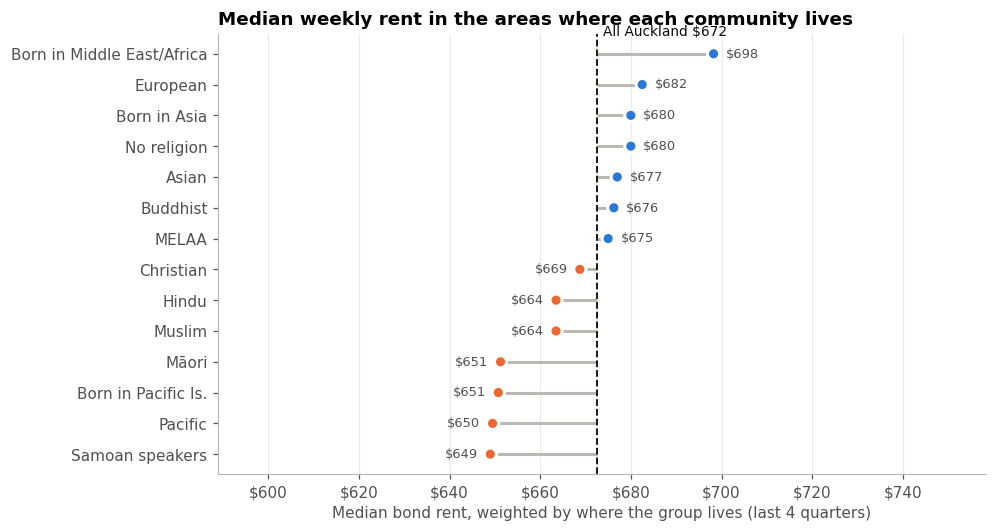

In [10]:
r = typ.drop('All Auckland').sort_values('median_rent_weekly')
allr = typ.loc['All Auckland', 'median_rent_weekly']
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.hlines(range(len(r)), allr, r.median_rent_weekly, color=GREY, lw=2, zorder=1)
ax.scatter(r.median_rent_weekly, range(len(r)), s=64, color=[ORANGE if v < allr else BLUE for v in r.median_rent_weekly],
           edgecolor='white', linewidth=2, zorder=2)
ax.axvline(allr, color=INK, lw=1.2, ls='--')
ax.annotate(rf'All Auckland \${allr:.0f}', (allr, len(r) - 0.4), xytext=(4, 0), textcoords='offset points', fontsize=9, color=INK)
for y, v in enumerate(r.median_rent_weekly):
    ax.annotate(rf'\${v:.0f}', (v, y), xytext=(8 if v >= allr else -8, 0), textcoords='offset points',
                ha='left' if v >= allr else 'right', va='center', fontsize=8.5, color=MUTED)
ax.set_yticks(range(len(r)), r.index); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: rf'\${v:.0f}'))
ax.set_xlim(r.median_rent_weekly.min() - 60, r.median_rent_weekly.max() + 60)
ax.set(title='Median weekly rent in the areas where each community lives',
       xlabel='Median bond rent, weighted by where the group lives (last 4 quarters)')
fig.savefig(VIZ / '07_rent_by_community.png'); plt.show()

**Reading this:**
- Each figure describes **the areas where members live**: the median across SA2s weighted by the group's head count, so half of the community lives in SA2s with an area figure at or below it. It is not what members of the community pay or earn.
- **The differences are smaller than you might expect: $649 to $698 a week, against $672 for all Auckland.** Every community lives across a wide mix of suburbs.
- Pacific, Samoan-speaking and Māori Aucklanders live where rent is about $20–25/wk lower, but **incomes there are lower still**, so their rent-to-income is the highest (30–31%, against 29% for Auckland).
- **Muslim and Hindu** communities live where rent is $664/wk, about $9 below Auckland, at a rent-to-income of 29–30%. Crime there is a little above average (33 per 1,000 against 29).
- Those communities' areas are also **cooling faster** (rent falling about 1–1.5% a year since 2024, against 0.8% for Auckland): good for tenants, weaker for landlords (see File 5).
- **Born in Middle East/Africa** lives in the dearest, lowest-crime areas, because the group includes South Africans on the North Shore.

*Limits:* rent is the SA2 bond median for all dwelling types, not what members of the community pay. Rent-to-income uses bond rent against SA2 household income (File 2), not the community's own income.

### Step 7: Hub profiles

In [11]:
# STEP 7: ONE ROW PER COMMUNITY: its hubs, and the rent, crime and schools in them (medians across hub SA2s).
hubs = c23[c23.is_hub]
prof = hubs.groupby('group').agg(hubs=('sa2_code', 'size'), people_in_hubs=('count', 'sum'),
                                 rent=('median_rent_weekly', 'median'), rent_3bed=('rent_3bed_house', 'median'),
                                 rent_to_income=('rent_to_income_pct', 'median'), cooling_pa=('cooling_pa', 'median'),
                                 crime=('crime_per_1000_residents', 'median'), schools=('schools', 'median')).reindex(list(GROUPS))
prof['cheapest_hubs'] = (hubs.sort_values('median_rent_weekly').groupby('group')
                             .apply(lambda x: ', '.join(f'{n} (${v:.0f})' for n, v in zip(x.sa2_name[:3], x.median_rent_weekly[:3])),
                                    include_groups=False))
summary = summary.join(prof[['cheapest_hubs']].rename(columns={'cheapest_hubs': 'cheapest_hubs'}))
prof.round(1)

,hubs,people_in_hubs,rent,rent_3bed,rent_to_income,cooling_pa,crime,schools,cheapest_hubs
group,,,,,,,,,
European,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Māori,40.0,38160.0,645.0,667.5,35.6,-1.6,41.5,1.0,"Point England North ($535), Wellsford ($549), Papakura Central ($551)"
Pacific,82.0,133002.0,647.6,668.2,32.1,-1.6,32.4,1.0,"Ōtāhuhu North West ($481), Ōtāhuhu North East ($481), Ōtāhuhu South West ($525)"
Asian,30.0,61590.0,716.2,702.0,27.5,-0.2,20.1,1.0,"Twin Parks Rise ($627), Newmarket ($628), Ormiston South East ($643)"
MELAA,2.0,636.0,682.9,712.5,31.9,-2.0,24.8,1.0,"Waterview ($631), Unsworth Heights West ($735)"
Christian,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
No religion,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Muslim,13.0,5190.0,675.0,687.5,31.6,-0.4,31.4,1.0,"Wesley West ($627), Māngere South East ($648), Mount Roskill South East ($654)"
Hindu,71.0,34788.0,669.5,692.0,29.6,-1.1,31.4,1.0,"Hobson Ridge Central ($452), Papatoetoe Central East ($566), Papatoetoe Central West ($566)"


**Reading this:**
- **Muslim hubs** (13): median rent $675/wk, 3-bed house $688, rent-to-income 32%. The cheapest are **Wesley West ($627), Māngere South East ($648) and Mount Roskill South East ($654)**.
- **Hindu hubs** (71): $670/wk; the cheapest family-suitable ones are **Papatoetoe Central East and West ($566)**. Hobson Ridge Central ($452) is a CBD apartment SA2 (students), not a family area.
- **Pacific hubs** (82): $648/wk, with the lowest rents in **Ōtāhuhu ($481–525)**. Rents in Pacific and Māori hubs are falling fastest (−1.6% a year).
- **Asian hubs** (30): dearest of the large groups ($716) but lowest crime (20 per 1,000), with rents almost flat (−0.2%).
- The cheapest 'Born in Asia' hubs are CBD student apartments (Symonds Street, Hobson Ridge): look at the 3-bed house rent, not the all-dwelling median, for families.

*Schools* is the count of schools inside the SA2 (master file). File 3's 2 km and 3 km counts are better for families.

### Step 8: Maps

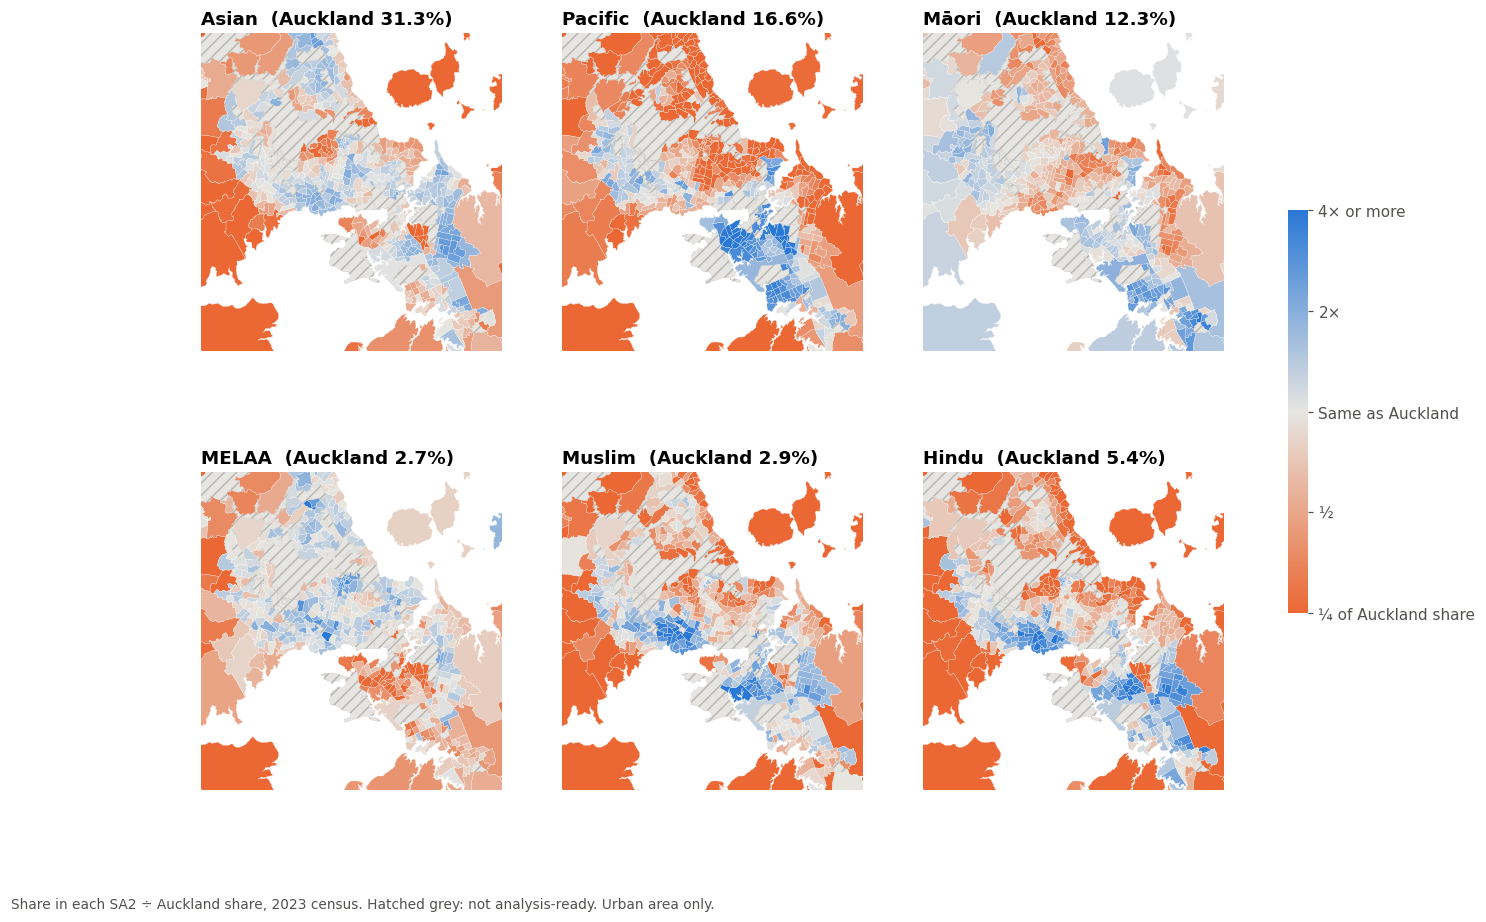

In [12]:
# STEP 8: LOCATION QUOTIENT MAPS. Diverging on log2(LQ): orange = rarer than across Auckland, blue = more common.
geo = gpd.read_file('data/boundaries/auckland_sa2_2023.geojson'); geo['sa2_code'] = geo['SA22023_V1_00'].astype(int)
MAPS = ['Asian', 'Pacific', 'Māori', 'MELAA', 'Muslim', 'Hindu']
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
for ax, g in zip(axes.flat, MAPS):
    x = geo[['sa2_code', 'geometry']].merge(c23[c23.group == g][['sa2_code', 'lq', 'analysis_ready']], on='sa2_code')
    x['l2'] = np.log2(x.lq.clip(lower=0.125))
    x[x.analysis_ready].plot(column='l2', cmap=DIV, vmin=-2, vmax=2, ax=ax, edgecolor='white', linewidth=0.15)
    x[~x.analysis_ready].plot(ax=ax, color='#e6e5e1', hatch='///', edgecolor=GREY, linewidth=0.15)
    ax.set_title(f'{g}  (Auckland {summary.loc[g, "pct_2023"]:.1f}%)'); ax.set_axis_off()
    ax.set_xlim(174.55, 175.0); ax.set_ylim(-37.1, -36.72)
sm = plt.cm.ScalarMappable(cmap=DIV, norm=plt.Normalize(-2, 2))
cb = fig.colorbar(sm, ax=axes, shrink=0.5, location='right', ticks=[-2, -1, 0, 1, 2])
cb.ax.set_yticklabels(['¼ of Auckland share', '½', 'Same as Auckland', '2×', '4× or more']); cb.outline.set_visible(False)
fig.text(0.01, 0.02, 'Share in each SA2 ÷ Auckland share, 2023 census. Hatched grey: not analysis-ready. Urban area only.',
         color=MUTED, fontsize=9)
fig.savefig(VIZ / '07_lq_maps.png'); plt.show()

**Reading this:** blue = more common than across Auckland, orange = rarer.
- **Pacific:** a solid block in Māngere, Ōtāhuhu, Ōtara and Manurewa, almost absent from the North Shore and the east.
- **Muslim:** two clusters, **Mount Roskill–Blockhouse Bay–Avondale** in the west and **Māngere–Papatoetoe** in the south.
- **Hindu:** the same two belts as Muslims (Mount Roskill–Sandringham and Papatoetoe–Manukau), plus Takanini.
- **Asian:** spread widely, strongest in the east (Howick, Botany, Ormiston), the North Shore (Albany), and central isthmus suburbs.
- **Māori:** strongest in the south (Manurewa, Papakura) and the west (Rānui, Massey).
- **MELAA:** the most even of all; small pockets in Mount Roskill and Waterview.

### Step 9: Save outputs

In [13]:
# STEP 9: SAVE. Long file (SA2 x group) for the dashboard and agent; per-group summary for headline answers.
p_all = long.pivot_table(index=['sa2_code', 'group', 'group_type'], columns='year', values=['count', 'pct'])
p_all.columns = [f'{a}_{y}' for a, y in p_all.columns]
out = (base[['sa2_code', 'sa2_name', 'area_type', 'population_2023', 'analysis_ready']]
       .merge(p_all.reset_index(), on='sa2_code')
       .merge(c23[['sa2_code', 'group', 'lq', 'is_hub']], on=['sa2_code', 'group'], how='left')
       .rename(columns={'lq': 'lq_2023'}))
out['share_change_pp_2013_2023'] = out.pct_2023 - out.pct_2013
f1, f2 = CLEAN / 'community_by_sa2.csv', CLEAN / 'community_summary.csv'
out.round(3).to_csv(f1, index=False)
summary.round(3).to_csv(f2, index_label='group')
chk, s2 = pd.read_csv(f1), pd.read_csv(f2)
assert not chk.duplicated(['sa2_code', 'group']).any() and chk.group.nunique() == len(GROUPS) == len(s2)
print(f'Saved {f1} ({len(chk):,} rows, {chk.sa2_code.nunique()} SA2s) and {f2} ({len(s2)} rows)')
print('Charts:', ', '.join(sorted(f.name for f in VIZ.glob('07_*.png'))))

Saved data\clean\community_by_sa2.csv (8,745 rows, 626 SA2s) and data\clean\community_summary.csv (14 rows)
Charts: 07_community_growth.png, 07_dissimilarity.png, 07_lq_maps.png, 07_rent_by_community.png


# File 7: Communities - Summary

## Key findings
| Question | Answer |
|---|---|
| Fastest-growing communities, 2013–2023 | MELAA +79%, Asian +69%, Muslim +55%, Hindu +47%, Māori +43%, Pacific +41%; European +5%, Christian −6% |
| Auckland shares 2023 | European 50%, Asian 31%, Pacific 17%, Māori 12%, Hindu 5.4%, Muslim 2.9%, MELAA 2.7% |
| Most concentrated | Pacific and Samoan speakers (D about 0.5); Hindu 0.37, Asian 0.34, Muslim 0.33 |
| Trend | Nearly every community became **less concentrated**; Muslims, MELAA and the Asian-born dispersed fastest |
| Muslim areas | Māngere South / South East, Wesley, Avondale South, Mount Roskill. Emerging: Blockhouse Bay. 13 hubs, holding only 11% of Muslims |
| Hindu areas | Mount Roskill–Sandringham, Papatoetoe–Puhinui, Takanini. 71 hubs holding 39% |
| Pacific areas | Māngere, Ōtāhuhu, Ōtara, Manurewa. 82 hubs holding 49% |
| Where new growth went | Asian and Hindu growth into new subdivisions (Takanini, Hobsonville, Albany); Māori to the southern fringe (Drury) |
| Rent in the areas where members live | $649–698/wk against $672 for Auckland: small differences |
| Affordability (area-level) | Areas where Pacific, Samoan-speaking and Māori Aucklanders live have the lowest rent but the highest area ratio of new-tenancy rent to all-household income (30–31%) |
| Cheapest hubs | Muslim: Wesley West $627; Hindu: Papatoetoe Central $566; Pacific: Ōtāhuhu $481–525 |

## Caveats
- **Broad groups only.** Indian, Chinese, Filipino, Samoan, Tongan and similar need a separate Stats NZ download. 'Asian' mixes very different communities.
- **'Born in Middle East/Africa' includes South Africans**, so it is not a proxy for Middle Eastern or African communities. Use MELAA.
- Judaism (and Spiritualism) left out: their 2018 and 2023 counts are identical, which looks like a Stats NZ file error.
- People can give several ethnicities and religions; shares overlap.
- Rent is the SA2 bond median for all dwellings, not what the community pays. Some cheap hubs are CBD student apartments.
- Census counts are people by where they **live**, not where they worship or shop. No mosques, temples or halal shops in the data.
- 2013 counts are less complete (6% gave no ethnicity) and small-area counts are randomly rounded by Stats NZ.

## Outputs
- `data/clean/community_by_sa2.csv`: one row per SA2 × group (14 groups, 626 SA2s): count and share for 2013, 2018, 2023, share change, `lq_2023`, `is_hub`, `group_type`, area type, population, `analysis_ready`
- `data/clean/community_summary.csv`: one row per group: Auckland counts and shares by year, growth, dissimilarity 2013 and 2023, hub count, % in hubs, `area_weighted_*` rent, 3-bed rent, rent-to-income ratio, rent growth, cooling, crime and income in the areas where the group lives, cheapest hubs
- `visualizations/07_*.png`: 4 charts